# Indirect methods III (minimum propellant, fixed time, MEE)

This notebook solves the same fixed-time minimum-propellant problem as the Cartesian mass-optimal case, but using modified equinoctial elements (MEE).

For comparison, see the [Cartesian mass-optimal notebook](./pontryagin_cartesian_mass.ipynb). The time-optimal counterpart in MEE is in [equinoctial time-optimal notebook](./pontryagin_equinoctial_time.ipynb).

In [1]:
import pykep as _pk
import numpy as np
import heyoka as hy
import pygmo as pg
import pygmo_plugins_nonfree as ppnf
import time

from matplotlib import pyplot as plt

## Manual construction of the TPBVP
We consider a spacecraft of mass $m$ under central gravity with parameter $\mu$, equipped with low-thrust propulsion of maximum thrust $T_{\max}=c_1$ and effective exhaust velocity $c_2=I_{sp}g_0$.

The state is $[p,f,g,h,k,L,m]^T$, where $[p,f,g,h,k,L]^T$ are prograde modified equinoctial elements (see [Elements page](../elements.rst)).

The controlled dynamics are

$$
\begin{array}{l}
\dot p = \sqrt{\frac p\mu} \frac{2p}{w} i_t\, c_1 \frac{u}{m} \\
\dot f = \sqrt{\frac p\mu} \left\{i_r \sin L + \left[ (1+w)\cos L + f \right] \frac{i_t}{w} - (h\sin L-k\cos L)\frac{g i_n}{w} \right\} c_1\frac{u}{m} \\
\dot g = \sqrt{\frac p\mu} \left\{ - i_r\cos L + \left[ (1+w)\sin L + g \right] \frac{i_t}{w} + (h\sin L-k\cos L)\frac{f i_n}{w} \right\} c_1\frac{u}{m} \\
\dot h = \sqrt{\frac p\mu} \frac{s^2 i_n}{2w}\cos L\, c_1\frac{u}{m} \\
\dot k = \sqrt{\frac p\mu} \frac{s^2 i_n}{2w}\sin L\, c_1\frac{u}{m} \\
\dot L = \sqrt{\frac p\mu}\left\{\mu\left(\frac wp\right)^2 + \frac{1}{w}\left(h\sin L-k\cos L\right)i_n c_1\frac{u}{m} \right\} \\
\dot m = -\frac{c_1}{c_2}u
\end{array}
$$

with $w = 1 + f\cos L + g\sin L$, $s^2 = 1 + h^2 + k^2$, control constraints $0\le u\le1$, and $\hat{\mathbf i}_{\tau}=[i_r,i_t,i_n]^T$ such that $\|\hat{\mathbf i}_{\tau}\|=1$.

A compact form is

$$
\left\{
\begin{array}{l}
\dot{\mathbf x} = \frac{c_1u(t)}{m}\mathbf B(\mathbf x)\hat{\mathbf i}_{\tau} + \mathbf D(\mathbf x) \\
\dot m = -\frac{c_1}{c_2}u(t)
\end{array}
\right.,
$$

where

$$
\sqrt{\frac{\mu}{p}}\mathbf B(\mathbf x)=
\left[
\begin{array}{ccc}
0 & \frac{2p}{w} & 0 \\
\sin L & \frac{(1+w)\cos L + f}{w} & -\frac{g}{w}(h\sin L-k\cos L) \\
-\cos L & \frac{(1+w)\sin L + g}{w} & \frac{f}{w}(h\sin L-k\cos L) \\
0 & 0 & \frac{s^2}{2w}\cos L \\
0 & 0 & \frac{s^2}{2w}\sin L \\
0 & 0 & \frac{1}{w}(h\sin L-k\cos L)
\end{array}
\right],
$$

and

$$
\mathbf D(\mathbf x)=\left[0,0,0,0,0,\sqrt{\frac{\mu}{p^3}}w^2\right]^T.
$$

Using `heyoka`, we now define symbolic variables for states, controls, and costates.

In [2]:
# State variables
p, f, g, h, k, L, m = hy.make_vars("p", "f", "g", "h", "k", "L", "m")
# Costate variables
lp, lf, lg, lh, lk, lL, lm = hy.make_vars(
    "lp", "lf", "lg", "lh", "lk", "lL", "lm"
)
# Control variables: throttle and RTN thrust direction
u, i_r, i_t, i_n = hy.make_vars("u", "ir", "it", "in")

To keep the derivation readable, we define compact expressions and vectorized groupings.

In [3]:
# Reusable scalar expressions
w = 1 + f * hy.cos(L) + g * hy.sin(L)
s2 = 1 + h * h + k * k
B = np.array(
    [
        [0, 2 * p / w, 0.0],
        [
            hy.sin(L),
            ((1 + w) * hy.cos(L) + f) / w,
            -g / w * (h * hy.sin(L) - k * hy.cos(L)),
        ],
        [
            -hy.cos(L),
            ((1 + w) * hy.sin(L) + g) / w,
            f / w * (h * hy.sin(L) - k * hy.cos(L)),
        ],
        [0, 0, s2 / w / 2.0 * hy.cos(L)],
        [0, 0, s2 / w / 2.0 * hy.sin(L)],
        [0, 0, 1.0 / w * (h * hy.sin(L) - k * hy.cos(L))],
    ]
) * hy.sqrt(p / hy.par[0])

D = np.array([0.0, 0.0, 0.0, 0.0, 0.0, hy.sqrt(hy.par[0] / p / p / p) * w * w])

i_vers = np.array([i_r, i_t, i_n])
lx = np.array([lp, lf, lg, lh, lk, lL])

The dynamics can then be written as:

In [4]:
# Dynamics
fx = np.dot(B, i_vers) * u * hy.par[1] / m + D
fm = - hy.par[1] / hy.par[2] * u

We introduce the regularized Hamiltonian ($\mathbf x$ is the full state and $\boldsymbol\lambda$ the full costate):

$$
\mathcal H(\mathbf x, \boldsymbol\lambda, \mathbf u) = \boldsymbol\lambda_x \cdot \mathbf f_x + \lambda_m f_m + \lambda_0\frac{c_1}{c_2}\left(u-\epsilon\log\left(u(1-u)\right)\right).
$$

The logarithmic barrier regularizes throttle switching and recovers near bang-bang behavior as $\epsilon\to0^+$.

In [5]:
# Regularized Hamiltonian
H_full = (lx @ fx + lm * fm + hy.par[4] * hy.par[1] / hy.par[2] * (u - hy.par[3] * hy.log(u * (1 - u))))
# Switching function rho from first-order optimality conditions
BTlam = B.T@lx 
BTlam_norm = hy.sqrt(BTlam @ BTlam)
rho = 1. - hy.par[2] * BTlam_norm / m / hy.par[4] - lm / hy.par[4]


Constants are passed in `heyoka` as $[\mu, c_1, c_2, \epsilon, \lambda_0]$, with $c_1=T_{\max}$ and $c_2=I_{sp}g_0$. Hence $\frac{c_1}{c_2}=\frac{T_{\max}}{I_{sp}g_0}$.

And write the resulting Hamiltonian system:

$$
\left\{
\begin{array}{l}
\dot{\mathbf x} = \frac{\partial \mathcal H}{\partial \mathbf \lambda} \\
\dot{\mathbf \lambda} = - \frac{\partial \mathcal H}{\partial \mathbf x} \\
\end{array}\right.
$$

In [6]:
# Augmented equations of motion
rhs = [
    hy.diff(H_full, var)
    for var in [lp, lf, lg, lh, lk, lL, lm, p, f, g, h, k, L, m]
]
for j in range(7, 14):
    rhs[j] = -rhs[j]

Pontryagin's minimum principle requires pointwise minimization over admissible controls

$$
\mathbf u^*(t)=\arg\min_{\mathbf u\in\mathcal U}\mathcal H(\mathbf x,\boldsymbol\lambda,\mathbf u),
$$

with $\mathcal U=\{(u,\hat{\mathbf i}_{\tau})\,|\,0\le u\le 1,\ \|\hat{\mathbf i}_{\tau}\|=1\}$.

For this problem, the minimizer is:

In [7]:
# PMP minimizer: RTN thrust direction anti-parallel to B^T lambda
# Smoothed throttle law from regularized Hamiltonian minimization
argmin_H_full = {
    i_r: -BTlam[0] / BTlam_norm,
    i_t: -BTlam[1] / BTlam_norm,
    i_n: -BTlam[2] / BTlam_norm,
    u: 2.
    * hy.par[3]
    / (rho + 2 * hy.par[3] + hy.sqrt(rho * rho + 4. * hy.par[3] * hy.par[3])),
}

After substitution, controls become smooth functions of state and costate. The TPBVP is then solved on the closed augmented dynamics.

In [8]:
rhs = hy.subs(rhs, argmin_H_full)

# We also build the Hamiltonian as a function of the state / co-state only
# (i.e. no longer of controls now solved thanks to the minimum principle)
H = hy.subs(H_full, argmin_H_full)

The next block instantiates the `heyoka` integrator and helper evaluators used for diagnostics and shooting.

In [9]:
# Compile Hamiltonian evaluator (pars = [mu, c1, c2, eps, lambda0])
H_func = hy.cfunc([H], [p, f, g, h, k, L, m , lp, lf, lg, lh, lk, lL, lm ])
# Compile optimal throttle evaluator
u_func = hy.cfunc(
    [argmin_H_full[u]], [p, f, g, h, k, L, m , lp, lf, lg, lh, lk, lL, lm ]
)
# Compile switching-function evaluator
rho_func = hy.cfunc([rho], [p, f, g, h, k, L, m , lp, lf, lg, lh, lk, lL, lm ])
# Compile optimal RTN thrust-direction evaluator
i_vers_func = hy.cfunc(
    [argmin_H_full[i_r], argmin_H_full[i_t], argmin_H_full[i_n]], [p, f, g, h, k, L, m , lp, lf, lg, lh, lk, lL, lm ]
)
# Assemble Taylor adaptive integrator
full_state = [p, f, g, h, k, L, m , lp, lf, lg, lh, lk, lL, lm ]
sys = [(var, dvar) for var, dvar in zip(full_state, rhs)]
ta = hy.taylor_adaptive(sys, state=[1.0] * 14, compact_mode=True)

In [10]:
var_sys = hy.var_ode_sys(sys, args = [lp,lf,lg,lh,lk,lL,lm, hy.par[4]])
ta = hy.taylor_adaptive(var_sys, compact_mode=True)

## Constructing the TPBVP using pykep

`pykep` provides pre-assembled components that reproduce the manually derived objects above.

In practice, these are preferred for robust workflows, while the manual derivation is useful for understanding and debugging.

In [11]:
# The Taylor integrator
ta = _pk.ta.get_peq(1e-16, _pk.optimality_type.MASS)
# The Variational Taylor integrator
ta = _pk.ta.get_peq_var(1e-16, _pk.optimality_type.MASS)
# The Hamiltonian
H_func = _pk.ta.get_peq_H_cfunc(_pk.optimality_type.MASS)
# The switching function
SF_func = _pk.ta.get_peq_SF_cfunc(_pk.optimality_type.MASS)
# The magnitude of the throttle
u_func = _pk.ta.get_peq_u_cfunc(_pk.optimality_type.MASS)
# The thrust direction
i_vers_func = _pk.ta.get_peq_i_vers_cfunc(_pk.optimality_type.MASS)
# The dynamics cfunc
dyn_func = _pk.ta.get_peq_dyn_cfunc(_pk.optimality_type.MASS)

## Solving in single shooting

The previous section was primarily pedagogical. From here onward, we use dedicated `pykep` classes.

As a first test case, we use the same simple transfer as the [Cartesian mass-optimal notebook](./pontryagin_cartesian_mass.ipynb). The case is well conditioned, so we can start directly with small $\epsilon$ and solve without continuation.

A harder case requiring continuation can be treated with the same workflow.

In [12]:
# Testcase 1 
posvel0 = [
    [34110913367.783306, -139910016918.87585, -14037825669.025244],
    [29090.9902134693, 10000.390168313803, 1003.3858682643288],
]
posvelf = [
    [-159018773159.22266, -18832495968.945133, 15781467087.350443],
    [2781.182556622003, -28898.40730995848, -483.4533989771214],
]

tof = 250
mu = _pk.MU_SUN
eps = 1e-5
T_max = 0.6
Isp = 3000
m0 = 1500
n_rev=0

In [13]:
# Testcase based on Jiang's paper: https://doi.org/10.2514/1.52476
#eq0 = [149654984885.857604980468750, -0.003159967920532, 0.016705492433629, 0.000007081860749, 0.000002593720250, 0.240005388978809]
#eqf = [108204221662.185256958007812, -0.004499485159298, 0.005049416150669, 0.006838004167958, 0.028831463943950, 2.045599177147440]
#
#m0 = 1500.0
#mu = 1.32712440018e20
#T_max = 0.33
#Isp = 3800.0
#g0 = 9.80665
#tof = 1000.0
#eps = 1.e-5
#n_rev=4 #3,4,5 possible
#
#posvel0 = pk.mee2ic(eq0, mu)
#posvelf = pk.mee2ic(eqf, mu)


We instantiate the shooting method using the UDP provided by `pykep`:

In [14]:
udp = _pk.trajopt.pontryagin_equinoctial_mass(
    posvel0=posvel0,
    posvelf=posvelf,
    tof=tof,
    mu=mu,
    eps=eps,
    lambda0 = None, # use 0.3 in case no normalization is seeked.
    T_max=T_max,
    Isp=Isp,
    m0=m0,
    n_rev = n_rev,
    L=_pk.AU,
    MU=mu,
    MASS=m0,
    with_gradient=True,
    taylor_tolerance=1e-10, # lower tolerances with multiple rev can be an issue
    taylor_tolerance_var=1e-4,
)
prob = pg.problem(udp)
prob.c_tol = 1e-6

The resulting TPBVP can be solved with interior-point optimizers or root-finding methods on boundary residuals.

Here we use IPOPT (via `pagmo`) and a MINPACK wrapper (via `scipy.optimize.root`).

In [15]:
ip = pg.ipopt()
ip.set_numeric_option("tol", 1e-9)  # Relative convergence tolerance
ip.set_integer_option("max_iter", 50)  # Maximum iterations
ip.set_integer_option("print_level", 0)  # Suppress IPOPT console output
ip.set_string_option(
    "sb", "yes"
)
ip.set_string_option(
    "nlp_scaling_method", "none"
)  # Disable IPOPT automatic scaling
ip.set_string_option(
    "mu_strategy", "adaptive"
)  # Adaptive barrier update strategy
ipopt = pg.algorithm(ip)

MINPACK is available via scipy and is missing in the current pygmo version, but we can quickly provide a wrapper as a UDA:

In [16]:
class my_solver:
    def __init__(self, gradient):
        self.gradient = gradient
    def evolve(self, pop: pg.population):
        from scipy.optimize import root
        prob = pop.problem
        x0 = pop.champion_x
        n = pop.problem.get_nx()
        if self.gradient:
            res = root(lambda x: prob.fitness(x)[1:], x0, method="hybr", tol=1e-8, options = {"factor": 1., "diag": [1]*8}, jac=lambda x: prob.gradient(x).reshape(n,n))  # factor=1.0 is critical for robustness
        else:
            res = root(lambda x: prob.fitness(x)[1:], x0, method="hybr", tol=1e-8, options = {"factor": 1., "diag": [1]*8})  # factor=1.0 is critical for robustness
        pop.set_x(0, res["x"])
        return pop
    def get_name(self):
        return "Minpack hybrd routine"

minpack = pg.algorithm(my_solver(False))
minpack_g = pg.algorithm(my_solver(True))

We use a multi-start strategy, which is generally good practice for indirect shooting due to sensitivity to initialization. In this easy case, multiple starts are mainly used to report robustness.

In [17]:
def multistart(algo, n_trials=50):
    masses = []
    xs = []
    total_time = 0.0
    success=0

    for i in range(n_trials):
        pop = pg.population(prob,1)
        time_start = time.time()
        pop = algo.evolve(pop)
        time_end = time.time()
        total_time += time_end - time_start
        if prob.feasibility_f(pop.champion_f):
            print(".", end="")
            udp.fitness(pop.champion_x)
            xs.append(pop.champion_x)
            masses.append(udp.ta.state[6])
            success+=1
        else:
            print("x", end="")
    if masses:
        print(f"\nFinal mass is: {masses[0]*udp.MASS}")
        print(f"Hamiltonian at the final point is: {H_func(udp.ta.state, pars=udp.ta.pars)} \n")
        print(f"Total time to success: {total_time:.3f} seconds")
        print(f"Number of successes: {success} over {n_trials} trials ({success/n_trials*100:.1f} %)")
    else:
        print("\nNo success")
    return pop

In [18]:
pop = multistart(ipopt, n_trials=10)

.....xx..x
Final mass is: 1259.900882320778
Hamiltonian at the final point is: [-0.03600518] 

Total time to success: 4.875 seconds
Number of successes: 7 over 10 trials (70.0 %)


In [19]:
pop = multistart(minpack_g, n_trials=10)

.xxx......
Final mass is: 1259.9008822275023
Hamiltonian at the final point is: [-0.03600518] 

Total time to success: 0.921 seconds
Number of successes: 7 over 10 trials (70.0 %)


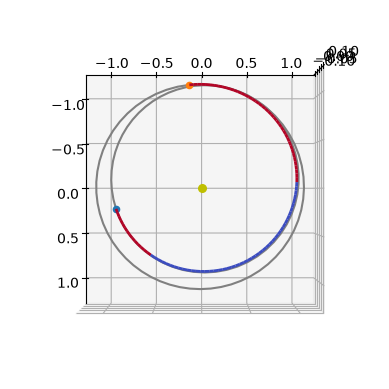

In [20]:
ax = udp.plot(pop.champion_x)
ax.view_init(90,0)

In these plots, thrust arcs are shown in red and coast (ballistic) arcs in blue.

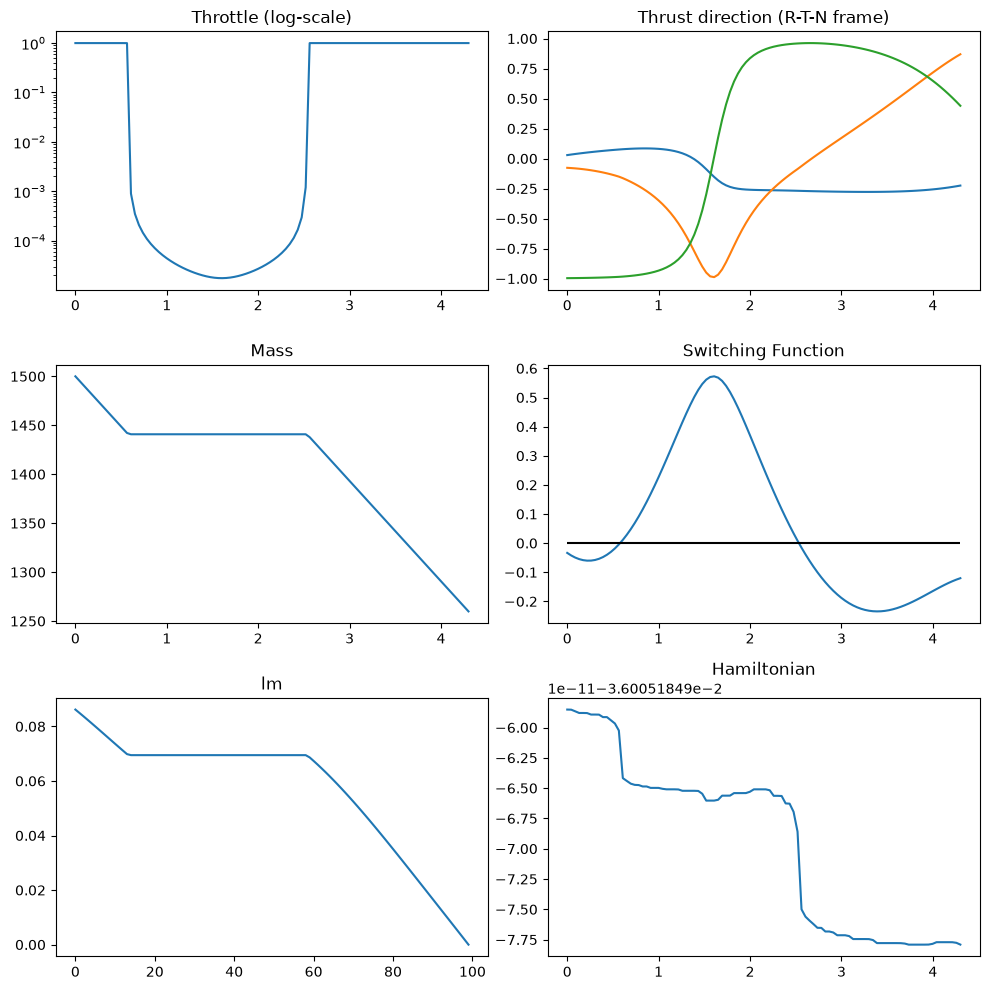

In [21]:
udp.plot_misc(pop.champion_x);